In [11]:
from pathlib import Path

from src.load_spectra import BOSZSpectra
from src.load_telluric import TelluricSpectra
from src.model import ContinuumNormalizer

import numpy as np
from matplotlib import pyplot as plt

In [12]:
bosz_root = Path("/home/mward19/nobackup/autodelete/bosz-spectra")
telluric_root = Path("/home/mward19/nobackup/autodelete/telluric")

In [13]:
# Same parameters as the caches the NMFs were built from, so nothing is recomputed
bosz = BOSZSpectra(
    bosz_root / Path("data"),
    300_000,
    115_000,
    D=3000,
    wave_min=3000,
    wave_max=7000,
    cache_dir=bosz_root / Path("processed-harps"),
    spectra_per_file=1000,
)
telluric = TelluricSpectra(
    telluric_root / Path("TellPCA_3000_10500_R120000.fits"),
    D=3000,
    wave_min=3000,
    wave_max=7000,
    R_out=115_000,
    n_pca=4,
    t_floor=1e-10,
    cache_dir=telluric_root / Path("processed"),
)

Parsing root directory: 100%|██████████| 628620/628620 [00:08<00:00, 78333.52file/s]


In [14]:
wave = bosz.wave_out
# Finds nmf_F_3b9d9a3bfc.npy and nmf_G_a406df2c65.npy in the caches above instead of recomputing;
# F_kwargs are the get_F settings that file was made with (they are part of its name)
cn = ContinuumNormalizer(
    bosz,
    telluric,
    flux_errors=1e-8 * np.ones(3000),
    order_wavelengths=wave,
    F_kwargs=dict(n_epochs=4, batch_size=1024),
)

Loaded cached F from /home/mward19/nobackup/autodelete/bosz-spectra/processed-harps
Loaded cached G from /home/mward19/nobackup/autodelete/telluric/processed


In [15]:
F_minibatch = cn.F.copy() # the cached MiniBatchNMF result, kept for comparison

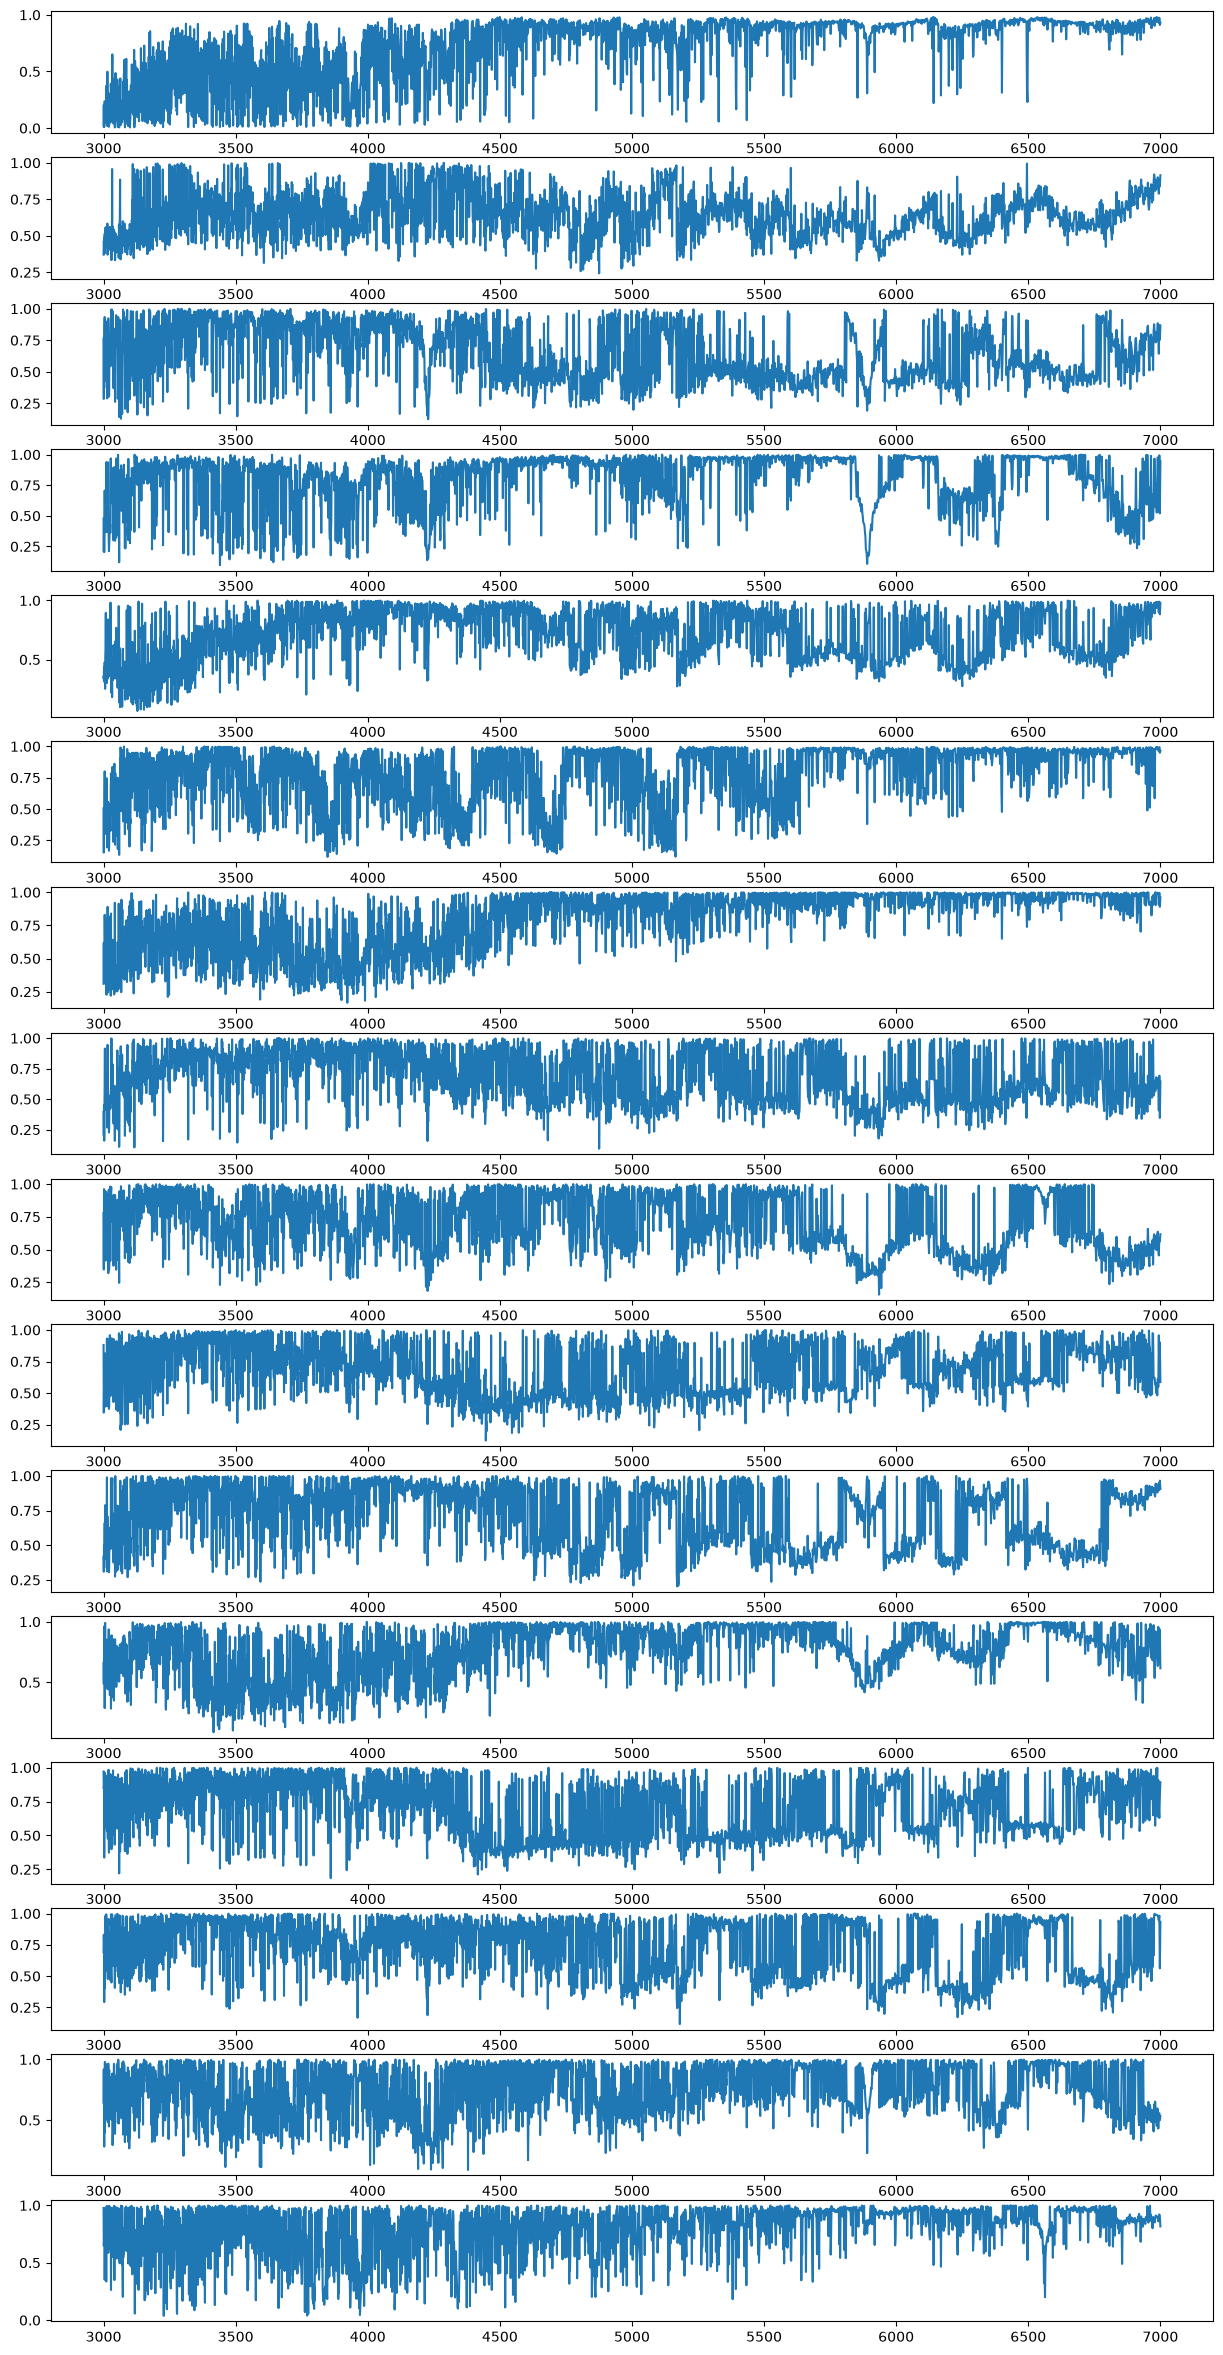

In [16]:
_n_vecs = 16
_fig, _axes = plt.subplots(_n_vecs, figsize=(15, 30))

for _i, _ax in enumerate(_axes):
    _ax.plot(wave, np.exp(-F_minibatch[_i]))

plt.show()

In [17]:
# MARCS atmospheres only, Teff <= 8000 K, as in the paper; then one ordinary NMF by coordinate
# descent. The paper runs 10_000 steps (~30 min); this is a short run to check the vectors.
cn.filter_spectra()
cn.fit_full(max_iter=100)
F_full = cn.F.copy()

Training on 396108 of 628620 spectra ({'atmos': ['mp', 'ms'], 'teff_max': 8000.0})
Loaded cached F from /home/mward19/nobackup/autodelete/bosz-spectra/processed-harps


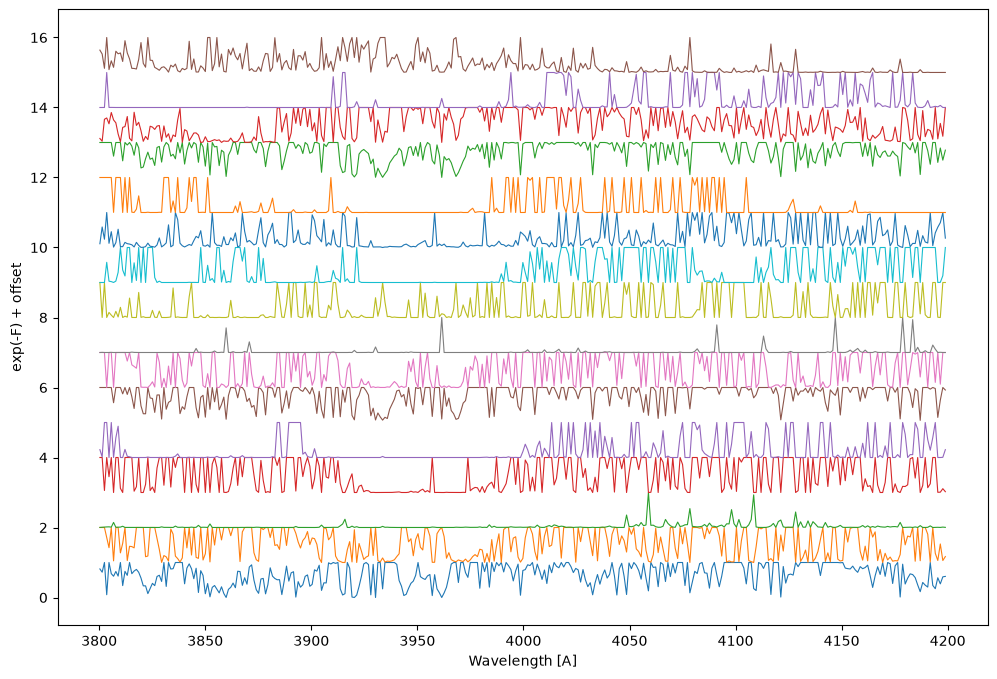

In [18]:
# Like Figure 1 of Casey et al. (2026): basis vectors exp(-F) with offsets, 3800-4200 A
_window = (wave >= 3800) & (wave <= 4200)
_fig, _ax = plt.subplots(figsize=(12, 8))
for _i, _f in enumerate(F_full):
    _ax.plot(wave[_window], np.exp(-_f[_window]) + _i, lw=0.8)
_ax.set_xlabel("Wavelength [A]")
_ax.set_ylabel("exp(-F) + offset")
plt.show()